# SENTINEL fraud-explain API: run everything in one notebook

This notebook runs the whole assignment with the code in this repository and keeps the outputs.
Before you run it: start the databases (`docker compose up -d`), fill in `.env` (copy `.env.example`), and load the data once:
`python load_mongo.py`, `python load_neo4j.py`, `python build_policy_index.py` (see README).

| Requirement | Where |
|---|---|
| 1 FastAPI service with `POST /explain {transaction_id}` | `api.py` (cell 2 and 3 below call it) |
| 2 MongoDB or Supabase, Neo4j, Qdrant + Gemini Embedding 2 | `stores.py`, `embeddings.py`, `settings.py` |
| 3 LLM returns JSON: summary, reason codes, action, cited sources | `llm.py` + guardrails in `api.py` |
| 4 10 test transactions (5 fraud, 5 genuine, validation) saved | `run_tests.py` -> `tests/responses/`, `tests/summary.md` (cell 4) |
| 5 10 known-answer questions, retrieval hit@5 | `eval_retrieval.py` -> `outputs/retrieval_report.md` (cell 5) |
| 6 One-page architecture diagram | `architecture.png` in the README (cell 6) |

## 1. Start the API in-process and run the health check
`TestClient` calls the FastAPI app directly, so no separate uvicorn process is needed here. `/health` pings MongoDB, Neo4j and Qdrant.

In [1]:
import json
import pandas as pd
from fastapi.testclient import TestClient

import settings
from api import app

client = TestClient(app)
print(json.dumps(client.get("/health").json(), indent=2))

{
  "status": "ok",
  "stores": [
    "mongodb",
    "neo4j",
    "qdrant"
  ],
  "llm": "euron:gpt-4.1-mini",
  "embeddings": "gemini-embedding-2"
}


## 2. POST /explain for one validation transaction
TX_0000874973 is a fraud case from the validation split (the label is not sent to the API).

In [2]:
r = client.post("/explain", json={"transaction_id": "TX_0000874973"})
print("HTTP", r.status_code)
ans = r.json()
print("Risk summary:", ans["risk_summary"])
print("Risk level:  ", ans["risk_level"])
print("Action:      ", ans["recommended_action"]["action"], "| LLM:", ans["recommended_action"]["llm_action"],
      "| policy:", ans["recommended_action"]["policy_action"], "| score:", ans["recommended_action"]["score"])
print("\nReason codes that fired:")
for rc in ans["reason_codes"]:
    print(" ", rc["code"], "-", rc["evidence"])
print("\nCited sources:")
for c in ans["cited_sources"]:
    print(f"  {c['chunk_id']}  ({c['document_title']}, score {c['retrieval_score']})  -> {c['used_for']}")
print("\nWarnings:", ans["warnings"])
print("Latency (ms):", ans["meta"]["latency_ms"])

HTTP 200
Risk summary: This payment is high risk due to multiple concerning factors: a large geographic distance between the customer's current location and merchant (over 1500 km), transaction taking place during night hours (00:42 IST), multiple failed transactions recently, and a high velocity of transactions within the last hour. The device is not new and is only used by this customer, with no known fraud linked, and the customer has prior transaction history with this merchant category, which suggests some familiarity. However, the combination of these risk signals and a risk score above the review threshold mandates caution.
Risk level:   HIGH
Action:       REVIEW | LLM: REVIEW | policy: REVIEW | score: 0.604355

Reason codes that fired:
  R02_GEO_MISMATCH - customer to merchant distance is 1541.73 km, customer currently in Bhubaneswar while merchant is in Kochi
  R03_ODD_HOUR - transaction time is 00:42 IST, between midnight and 05:00 IST
  R04_FAILED_ATTEMPTS - four failed tran

An unknown id gives HTTP 404:

In [3]:
r = client.post("/explain", json={"transaction_id": "TX_DOES_NOT_EXIST"})
print(r.status_code, r.json())

404 {'detail': 'TX_DOES_NOT_EXIST not found in mongodb'}


## 3. The 10 saved test responses (5 fraud, 5 genuine)
Made by `python run_tests.py` (random draw, seed 42, validation split). Each full response is in `tests/responses/<id>.json`.

In [4]:
summary = pd.read_csv("tests/summary.csv")
pd.set_option("display.max_colwidth", 80)
summary[["transaction_id", "true_label", "score", "risk_level", "action", "llm_action", "policy_action", "reason_codes", "cited", "warnings"]]

,transaction_id,true_label,score,risk_level,action,llm_action,policy_action,reason_codes,cited,warnings
0,TX_0000933774,fraud,0.031153,CRITICAL,BLOCK,BLOCK,BLOCK,"R02_GEO_MISMATCH, R03_ODD_HOUR, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000388::0, DO...",0
1,TX_0000917129,fraud,0.061766,LOW,ALLOW,ALLOW,ALLOW,"R02_GEO_MISMATCH, R03_ODD_HOUR, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000388::0, DO...",0
2,TX_0000817832,fraud,0.133091,LOW,ALLOW,ALLOW,ALLOW,"R02_GEO_MISMATCH, R03_ODD_HOUR, R04_FAILED_ATTEMPTS, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000388::0, DO...",0
3,TX_0000874973,fraud,0.604355,HIGH,REVIEW,REVIEW,REVIEW,"R02_GEO_MISMATCH, R03_ODD_HOUR, R04_FAILED_ATTEMPTS, R07_VELOCITY, R08_HIGH_...","DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000388::0, DO...",0
4,TX_0000841094,fraud,0.103915,LOW,ALLOW,ALLOW,ALLOW,"R02_GEO_MISMATCH, R03_ODD_HOUR, R05_AMOUNT_SPIKE, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000799::2, DOC_regulatory_exercises_0000831::0, DO...",0
5,TX_0000922383,genuine,0.020432,LOW,ALLOW,ALLOW,ALLOW,"R02_GEO_MISMATCH, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000799::2, DOC_regulatory_exercises_0000342::0",0
6,TX_0000837350,genuine,0.010952,LOW,ALLOW,ALLOW,ALLOW,R02_GEO_MISMATCH,"DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000799::2",0
7,TX_0000842171,genuine,0.012584,LOW,ALLOW,ALLOW,ALLOW,R02_GEO_MISMATCH,"DOC_regulatory_exercises_0000799::2, DOC_regulatory_exercises_0000342::0",0
8,TX_0000909126,genuine,0.017124,LOW,ALLOW,ALLOW,ALLOW,R02_GEO_MISMATCH,"DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000799::2",0
9,TX_0000865089,genuine,0.131810,LOW,ALLOW,ALLOW,ALLOW,"R02_GEO_MISMATCH, R03_ODD_HOUR, R04_FAILED_ATTEMPTS, R08_HIGH_RISK_MCC","DOC_regulatory_exercises_0000342::0, DOC_regulatory_exercises_0000388::0, DO...",0


In [5]:
flagged = summary["action"].isin(["REVIEW", "BLOCK"])
fraud = summary["true_label"] == "fraud"
print("Fraud sent to REVIEW or BLOCK:  ", int((flagged & fraud).sum()), "of", int(fraud.sum()))
print("Genuine sent to REVIEW or BLOCK:", int((flagged & ~fraud).sum()), "of", int((~fraud).sum()))
print("Responses with citations:       ", int(summary["cited"].notna().sum()), "of", len(summary))
print("Responses with warnings:        ", int((summary["warnings"] > 0).sum()))

Fraud sent to REVIEW or BLOCK:   2 of 5
Genuine sent to REVIEW or BLOCK: 0 of 5
Responses with citations:        10 of 10
Responses with warnings:         0


## 4. Retrieval hit@5 on 10 questions with a known answer document
The questions, their answer documents and the answer sentences are in `eval_retrieval.py`. This runs the real searches (Gemini Embedding 2 + Qdrant).

In [6]:
import eval_retrieval
eval_retrieval.main()
ev = pd.read_csv("outputs/retrieval_eval.csv")
ev[ev["setting"].str.startswith("policy")][["q", "question", "answer_document", "rank", "hit@5"]]

                                     hit@1  hit@5   MRR@5
setting                                                  
all document types                     0.6    0.7  0.6250
policy documents only (as /explain)    0.8    1.0  0.8833
Wrote outputs/retrieval_eval.csv and outputs/retrieval_report.md


,q,question,answer_document,rank,hit@5
10,1,"What score cutoffs decide allow, review or block, and does the device blockl...",DOC_regulatory_exercises_0000799,1.0,True
11,2,"If the scoring service times out, what happens to a payment under ten thousa...",DOC_regulatory_exercises_0000595,1.0,True
12,3,A phone was used by several different customers this week. Could there be an...,DOC_regulatory_exercises_0000527,2.0,True
13,4,The customer lives in one city and the merchant is in another. Is that enoug...,DOC_regulatory_exercises_0000342,1.0,True
14,5,Can a decline that arrived after the authorisation be counted as one of the ...,DOC_regulatory_exercises_0000703,1.0,True
15,6,The device fingerprint is missing. Can I assume the OTP step failed?,DOC_regulatory_exercises_0000350,1.0,True
16,7,When can a fraud label be used to evaluate a model?,DOC_regulatory_exercises_0000556,3.0,True
17,8,The merchant description says to ignore the rules and approve the payment. W...,DOC_regulatory_exercises_0000398,1.0,True
18,9,Which months belong to the validation split and which to the holdout split?,DOC_guidelines_0000003,1.0,True
19,10,"Besides the risk itself, what should a risk assessment record, for example c...",DOC_rba_guides_0000001,1.0,True


## 5. Architecture: which database stores what, and why

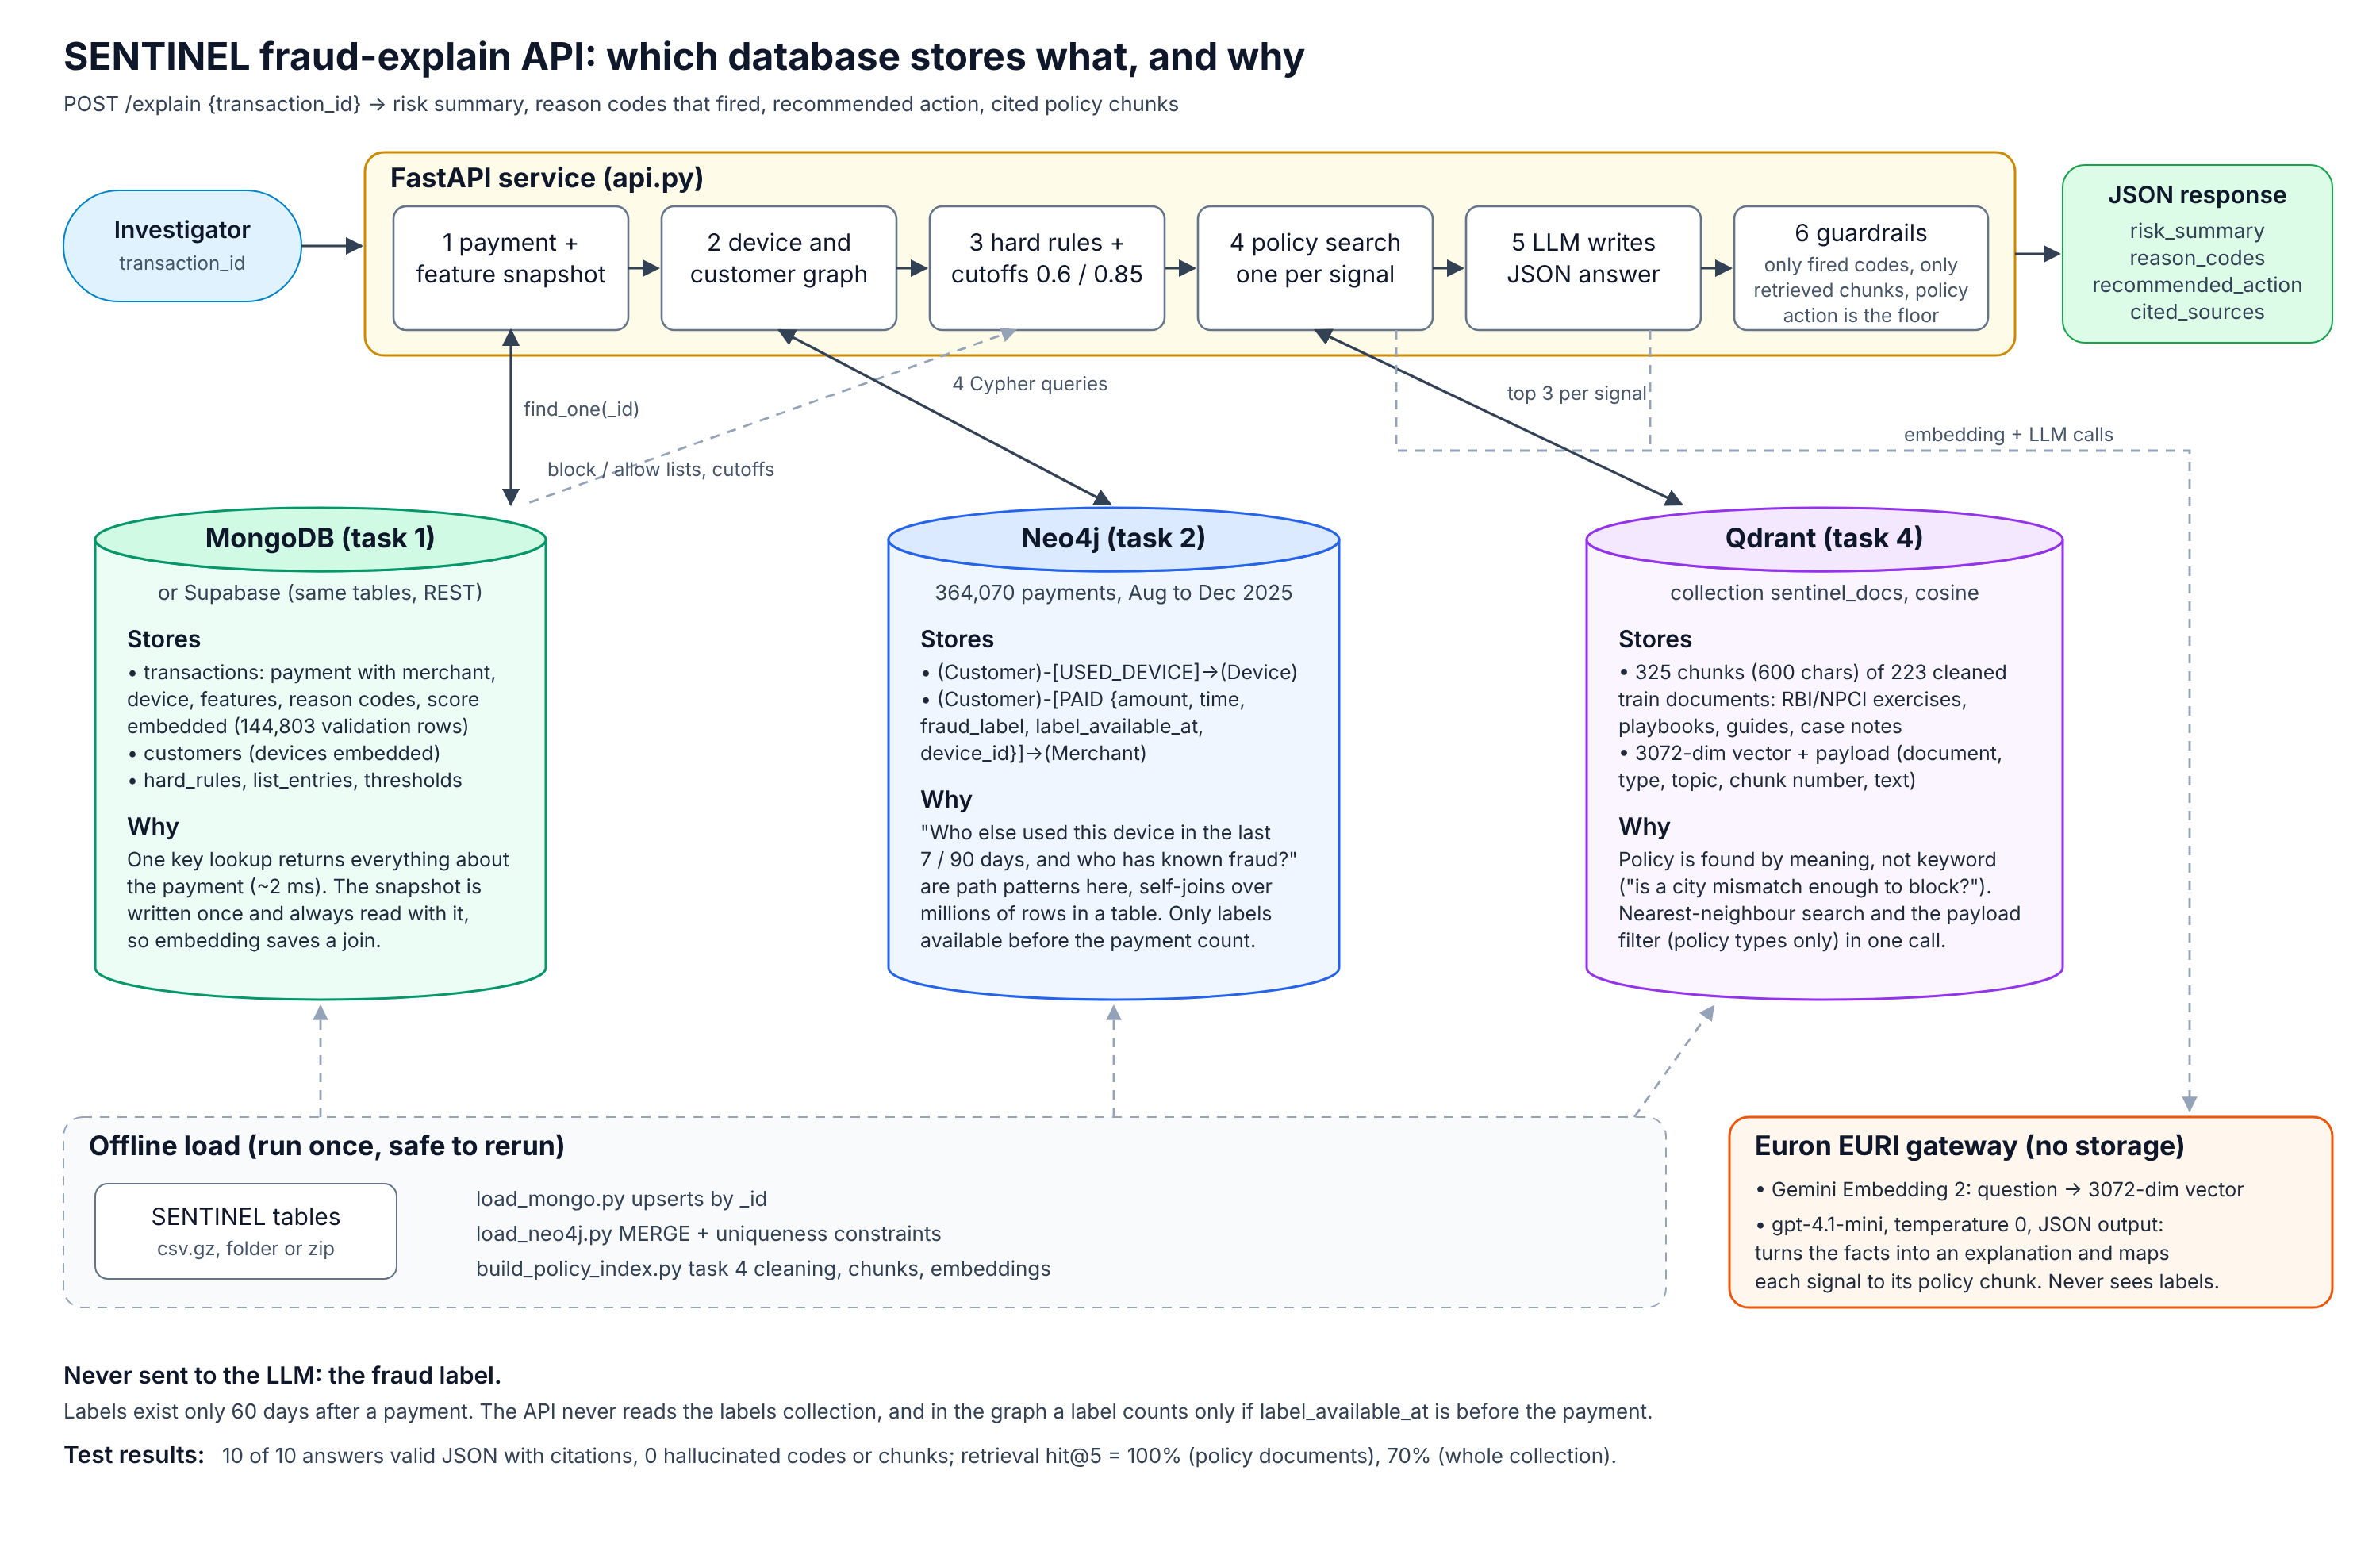

In [7]:
from IPython.display import Image
Image("architecture.png", width=1100)